# Electrification of Heat: descriptive analysis

The Electrification of Heat (EoH) demonstration project (2020–23) supplies the **real heat-pump
load** that is added to Low Carbon London households to build the synthetic heat-pump dataset.
Its three delivery contractors cover three regions: E.ON around Newcastle, Warmworks in
south-east Scotland and OVO in South East England. The OVO heat pumps are held out of training
and used only for the transfer test.

This notebook produces three tables and four figures:
- a data breakdown by contractor;
- the cohort's characteristics, in the same categories as the LCL table LCL_T2;
- a summary by heat-pump type;
- the temperature response, the seasonal and daily load shape, and a heat map that shares its
  colour scale with the LCL heat map.

**Data** (`Data/EoH/`):
- `eoh_cleaned_half_hourly.csv`: half-hourly readings for 739 properties.
- `9bbf3b4f-…csv`: the installation record for all 3,206 recruited households.

## 1. Setup

In [1]:
from pathlib import Path
import json
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
DATA_DIR = NB_DIR / "Data" / "EoH"
CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (CACHE_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

HH_CSV = DATA_DIR / "eoh_cleaned_half_hourly.csv"
META_CSV = DATA_DIR / "9bbf3b4f-5b33-4652-b385-d69ba68004d0.csv"
for p in [HH_CSV, META_CSV]:
    assert p.exists(), f"missing expected data file: {p}"

MAX_HH_KWH = 5.0          # 10 kW sustained for 30 min: above this is a register artefact
COMPLETE_MIN_SLOTS = 44   # a complete day has >= 44 of 48 half-hours
MIN_MONTHS = 6            # usable for the linkage: complete days in >= 6 calendar months
MIN_WINTER_DAYS = 60      # analysis cohort: more than 60 complete winter days
HDD_BASE = 15.5           # degree-day base used in the feature set
COLD_DAY_MAX_TEMP = 15.0  # beta_temp is fitted on days below this, as in the feature code
WINTER_MONTHS, SUMMER_MONTHS = (12, 1, 2), (6, 7, 8)

# Heat-map colour scale, shared with 01_lcl_analysis and with Figure HP_J3 of 04_hp_linkage_lcl_eoh,
# so the maps compare directly. Heat-pump load reaches about 1 kWh per half-hour.
HEATMAP_VMAX = 1.05

CONTRACTORS = ["E.ON", "Warmworks", "OVO"]
HP_ORDER = ["ASHP", "HT_ASHP", "GSHP", "Hybrid"]
HP_LABELS = {"ASHP": "Air source", "HT_ASHP": "High-temp. air source",
             "GSHP": "Ground source", "Hybrid": "Hybrid (HP + boiler)"}

In [2]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
WINTER_COLOR, SUMMER_COLOR = CAT["blue"], CAT["orange"]
CONTRACTOR_COLORS = {"E.ON": CAT["blue"], "Warmworks": CAT["orange"], "OVO": CAT["aqua"]}
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

SEQ_BLUE_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})


COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df


def hhmm_axis(ax, step_hours=3):
    # Label a 48-slot time-of-day x-axis; slot i spans [i, i+1) (period start).
    ticks = list(range(0, 49, step_hours * 2))
    ax.set_xticks(ticks)
    ax.set_xticklabels(["24:00" if t == 48 else f"{t // 2:02d}:{'00' if t % 2 == 0 else '30'}"
                        for t in ticks])


def binned_stats(x, y, edges, min_n=30):
    # Median and quartiles of y within bins of x; bins with fewer than min_n points are dropped.
    idx = np.digitize(x, edges) - 1
    rows = []
    for i in range(len(edges) - 1):
        sel = y[idx == i]
        if len(sel) >= min_n:
            rows.append({"centre": (edges[i] + edges[i + 1]) / 2, "n": len(sel),
                         "q25": np.percentile(sel, 25), "median": np.median(sel),
                         "q75": np.percentile(sel, 75)})
    return pd.DataFrame(rows)

## 2. Data loading: cumulative registers to half-hourly energy

**The energy columns are cumulative meter registers**, although nothing in their names says so.
Half-hourly energy is therefore the first difference within each property, in time order:

```
kwh(t) = Whole_System_Energy_Consumed(t) − Whole_System_Energy_Consumed(t − 1)
```

This is the energy over the half-hour **ending** at `t`, labelled here by its period start.

Three rules are applied:
1. **Nulls are dropped before differencing**, so each difference reaches back to the previous
   usable reading.
2. **Only differences whose previous reading is exactly 30 minutes earlier are kept.** A longer
   gap means a monitoring outage: the energy is real but belongs to a longer period. This rule
   matters far more than any spike filter. Of the 2,271 differences above 5 kWh, only 19 follow a
   reading 30 minutes earlier; the rest are correct totals across outages.
3. **The kept differences are clipped to [0, 5] kWh.** Negatives are register resets, and 5 kWh in
   30 minutes would be 10 kW sustained.

Exact zeros are kept: they are genuine standstill.

In [3]:
con = duckdb.connect()
con.execute("SET threads=6")
con.execute("PRAGMA preserve_insertion_order=false")
con.execute("PRAGMA memory_limit='8GB'")
con.execute(f"SET temp_directory='{(CACHE_DIR / 'duckdb_tmp').as_posix()}'")

con.execute(f"""
CREATE OR REPLACE VIEW eoh_raw AS
SELECT Property_ID AS property_id, Timestamp AS ts,
       Whole_System_Energy_Consumed AS kwh_cum, External_Air_Temperature AS ext_temp
FROM read_csv_auto('{HH_CSV.as_posix()}', sample_size=400000)
""")
con.execute("""
CREATE OR REPLACE VIEW eoh_delta_raw AS
SELECT property_id, ts, kwh_cum - lag(kwh_cum) OVER w AS d_kwh,
       date_diff('minute', lag(ts) OVER w, ts) AS gap_min, ext_temp
FROM (SELECT * FROM eoh_raw WHERE kwh_cum IS NOT NULL)
WINDOW w AS (PARTITION BY property_id ORDER BY ts)
""")

# Audit pass (one scan, cached): the counts quoted in the text above.
AUDIT_JSON = CACHE_DIR / "eoh_quality_audit.json"
if not AUDIT_JSON.exists():
    audit = con.execute(f"""
        SELECT
          (SELECT count(*) FROM eoh_raw)                                 AS raw_rows,
          (SELECT count(DISTINCT property_id) FROM eoh_raw)              AS raw_properties,
          (SELECT count(*) FROM eoh_raw WHERE kwh_cum IS NULL)           AS null_kwh_rows,
          (SELECT count(DISTINCT property_id) FROM eoh_delta_raw)        AS metered_properties,
          count(*) FILTER (WHERE gap_min IS NOT NULL)                    AS deltas,
          count(*) FILTER (WHERE gap_min = 30)                           AS deltas_30min,
          count(*) FILTER (WHERE gap_min > 30)                           AS deltas_gap,
          count(*) FILTER (WHERE d_kwh < 0)                              AS negative_all,
          count(*) FILTER (WHERE d_kwh < 0 AND gap_min = 30)             AS negative_30min,
          count(*) FILTER (WHERE d_kwh > {MAX_HH_KWH})                   AS spike_all,
          count(*) FILTER (WHERE d_kwh > {MAX_HH_KWH} AND gap_min = 30)  AS spike_30min,
          count(*) FILTER (WHERE d_kwh = 0)                              AS zero_all,
          min(d_kwh) AS min_delta, max(d_kwh) AS max_delta
        FROM eoh_delta_raw
    """).fetchdf().iloc[0].to_dict()
    AUDIT_JSON.write_text(json.dumps({k: float(v) for k, v in audit.items()}, indent=1))
AUDIT = {k: (int(v) if float(v).is_integer() else float(v))
         for k, v in json.loads(AUDIT_JSON.read_text()).items()}
print(AUDIT)

# Properties in the raw release, and whether each has any non-null register (one scan, cached).
RAW_PROPS = CACHE_DIR / "eoh_raw_properties.parquet"
if not RAW_PROPS.exists():
    con.execute(f"""
        COPY (SELECT property_id, count(*) AS n_rows, count(kwh_cum) AS n_nonnull
              FROM eoh_raw GROUP BY 1) TO '{RAW_PROPS.as_posix()}' (FORMAT PARQUET)
    """)
raw_props = pd.read_parquet(RAW_PROPS)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

{'raw_rows': 27718729, 'raw_properties': 739, 'null_kwh_rows': 3700193, 'metered_properties': 738, 'deltas': 24017798, 'deltas_30min': 24010453, 'deltas_gap': 7345, 'negative_all': 6, 'negative_30min': 3, 'spike_all': 2271, 'spike_30min': 19, 'zero_all': 73272, 'min_delta': -8.69399999999996, 'max_delta': 8959.728}


In [4]:
# The cleaned half-hourly table: kWh over the half-hour STARTING at ts.
EOH_HH = CACHE_DIR / "eoh_halfhourly.parquet"
if not EOH_HH.exists():
    con.execute(f"""
        COPY (
          SELECT property_id, ts - INTERVAL 30 MINUTE AS ts, d_kwh AS kwh, ext_temp
          FROM eoh_delta_raw
          WHERE gap_min = 30 AND d_kwh BETWEEN 0 AND {MAX_HH_KWH}
        ) TO '{EOH_HH.as_posix()}' (FORMAT PARQUET, COMPRESSION ZSTD)
    """)
con.execute(f"""
CREATE OR REPLACE VIEW hh AS
SELECT *, CAST(ts AS DATE) AS date, hour(ts) * 2 + minute(ts) // 30 AS slot, month(ts) AS month,
       CASE WHEN month(ts) IN {WINTER_MONTHS} THEN 'winter'
            WHEN month(ts) IN {SUMMER_MONTHS} THEN 'summer' ELSE 'shoulder' END AS season
FROM '{EOH_HH.as_posix()}'
""")

# Property-day totals.
PROPERTY_DAY = CACHE_DIR / "eoh_property_day.parquet"
if not PROPERTY_DAY.exists():
    con.execute(f"""
        COPY (
          SELECT property_id, date, count(*) AS n_slots, sum(kwh) AS kwh,
                 avg(ext_temp) AS ext_mean, count(ext_temp) AS n_ext,
                 any_value(month) AS month
          FROM hh GROUP BY property_id, date
        ) TO '{PROPERTY_DAY.as_posix()}' (FORMAT PARQUET)
    """)
property_day = pd.read_parquet(PROPERTY_DAY)
property_day["date"] = pd.to_datetime(property_day["date"])
property_day["is_winter"] = property_day.month.isin(WINTER_MONTHS)
property_day["is_summer"] = property_day.month.isin(SUMMER_MONTHS)

complete = property_day[property_day.n_slots >= COMPLETE_MIN_SLOTS].copy()
n_months = complete.groupby("property_id").month.nunique()
LINKAGE_READY = set(n_months[n_months >= MIN_MONTHS].index)
winter_days = complete[complete.is_winter].groupby("property_id").size()
COHORT = set(winter_days[winter_days > MIN_WINTER_DAYS].index)
analysis = complete[complete.property_id.isin(COHORT)].copy()
print(f"{property_day.property_id.nunique()} properties with usable data; "
      f"{len(LINKAGE_READY)} with complete days in >= {MIN_MONTHS} months; "
      f"{len(COHORT)} in the analysis cohort ({len(analysis):,} complete property-days)")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

738 properties with usable data; 726 with complete days in >= 6 months; 706 in the analysis cohort (489,321 complete property-days)


In [5]:
# Installation record: one row per recruited household.
meta_all = pd.read_csv(META_CSV, dtype=str).replace({"null": np.nan, "": np.nan}).set_index("Property_ID")
meta_all = meta_all.assign(
    contractor=meta_all.Delivery_Contractor,
    hp_type=meta_all.HP_Installed,
    dwelling_type=meta_all.House_Type.fillna("Not recorded"),
    dwelling_form=meta_all.House_Form.fillna("Not recorded"),
    heating_replaced=meta_all.Heat_Primary_Source.fillna("Not recorded"),
)
unmatched = set(property_day.property_id) - set(meta_all.index)
print(f"{len(meta_all):,} recruited households; {int(meta_all.hp_type.notna().sum())} heat pumps installed; "
      f"{len(unmatched)} metered properties without an installation record")

3,206 recruited households; 743 heat pumps installed; 0 metered properties without an installation record


## 3. Tables

### Table EoH_T1 - Data breakdown by delivery contractor

Each row is a subset of the row above it. "Usable for the linkage" is the threshold the
heat-pump linkage applies: complete days (at least 44 of 48 half-hours) in at least six calendar
months. The analysis cohort, used for every figure below, needs more than 60 complete winter
days. OVO is the contractor held out for the transfer test.

In [6]:
def by_contractor(ids) -> pd.Series:
    # Count properties per contractor for a set of Property_IDs.
    c = meta_all.loc[meta_all.index.intersection(list(ids)), "contractor"].value_counts()
    return c.reindex(CONTRACTORS).fillna(0).astype(int)


def days_by_contractor(days: pd.DataFrame) -> pd.Series:
    c = days.merge(meta_all[["contractor"]], left_on="property_id", right_index=True).contractor.value_counts()
    return c.reindex(CONTRACTORS).fillna(0).astype(int)


rows = {
    "Households recruited": meta_all.contractor.value_counts().reindex(CONTRACTORS),
    "  ...with a heat pump installed": meta_all[meta_all.hp_type.notna()].contractor.value_counts().reindex(CONTRACTORS),
    "  ...in the half-hourly release": by_contractor(raw_props.property_id),
    "  ...with a usable whole-system register": by_contractor(raw_props.loc[raw_props.n_nonnull > 0, "property_id"]),
    f"  ...usable for the linkage (complete days in >= {MIN_MONTHS} months)": by_contractor(LINKAGE_READY),
    f"  ...analysis cohort (> {MIN_WINTER_DAYS} complete winter days)": by_contractor(COHORT),
    "Complete property-days, analysis cohort": days_by_contractor(analysis),
}
t1 = pd.DataFrame(rows).T
t1["All"] = t1.sum(axis=1)
assert t1.loc["  ...in the half-hourly release", "All"] == AUDIT["raw_properties"], "a metered property lacks a contractor"
t1 = t1.map(lambda v: f"{int(v):,}")
savetable(t1, "EoH_T1_data_breakdown")
t1

saved -> tables/EoH_T1_data_breakdown.csv


contractor,E.ON,Warmworks,OVO,All
Households recruited,"1,403",866,937,"3,206"
...with a heat pump installed,309,305,129,743
...in the half-hourly release,307,304,128,739
...with a usable whole-system register,306,304,128,738
...usable for the linkage (complete days in >= 6 months),297,303,126,726
...analysis cohort (> 60 complete winter days),287,295,124,706
"Complete property-days, analysis cohort","191,840","211,541","85,940","489,321"


### Table EoH_T2 - Cohort characteristics by delivery contractor

Shares are of the analysis cohort within each contractor. The dwelling categories match the LCL
table LCL_T2. "Heating replaced" is the system the heat pump replaced. Four in five replaced a
gas boiler, which is why heat pumps are added only to gas-heated LCL homes.

In [7]:
cohort_meta = meta_all.loc[sorted(COHORT)]
TOP_REPLACED = 5
replaced_top = cohort_meta.heating_replaced.value_counts().index[:TOP_REPLACED].tolist()
cohort_meta = cohort_meta.assign(
    hp_label=cohort_meta.hp_type.map(HP_LABELS),
    replaced_grouped=cohort_meta.heating_replaced.where(cohort_meta.heating_replaced.isin(replaced_top), "Other"))

LEVELS = {
    "Dwelling type": ("dwelling_type", ["House", "Flat", "Maisonette", "Not recorded"]),
    "Dwelling form": ("dwelling_form", ["Detached", "Semi-Detached", "Mid-Terrace", "End-Terrace",
                                        "Flat", "Not recorded"]),
    "Heat-pump type": ("hp_label", [HP_LABELS[k] for k in HP_ORDER]),
    "Heating replaced": ("replaced_grouped", replaced_top + ["Other"]),
}
rows = []
for attribute, (col, levels) in LEVELS.items():
    for level in levels:
        row = {"Attribute": attribute, "Level": level}
        for label, df in [(c, cohort_meta[cohort_meta.contractor == c]) for c in CONTRACTORS] + [("All", cohort_meta)]:
            n = int((df[col] == level).sum())
            row[f"{label} n"] = n
            row[f"{label} %"] = f"{n / len(df):.1%}"
        rows.append(row)
t2 = pd.DataFrame(rows).set_index(["Attribute", "Level"])
t2 = t2[(t2.filter(like=" n").sum(axis=1) > 0)]   # drop levels absent from the cohort
savetable(t2, "EoH_T2_cohort_characteristics")
gas_share = cohort_meta.heating_replaced.str.startswith("Gas").mean()
print(f"heat pumps replacing a gas boiler: {gas_share:.1%}")
t2

saved -> tables/EoH_T2_cohort_characteristics.csv
heat pumps replacing a gas boiler: 80.0%


E.ON n E.ON %  Warmworks n  \
Attribute        Level                                               
Dwelling type    House                     272  94.8%          279   
                 Flat                       15   5.2%            9   
                 Maisonette                  0   0.0%            4   
                 Not recorded                0   0.0%            3   
Dwelling form    Detached                  108  37.6%          130   
                 Semi-Detached             122  42.5%           81   
                 Mid-Terrace                28   9.8%           37   
                 End-Terrace                14   4.9%           35   
                 Flat                       15   5.2%           12   
Heat-pump type   Air source                 69  24.0%          128   
                 High-temp. air source      81  28.2%          140   
                 Ground source              15   5.2%           10   
                 Hybrid (HP + boiler)      122  42.5%           17   
Heating replaced Gas Boiler - Combi        220  76.7%          126   
                 Gas Boiler - Standard      34  11.8%          100   
                 Electric - Storage         19   6.6%           25   
                 Oil Boiler                  0   0.0%           10   
                 Electric - Direct           0   0.0%           19   
                 Other                      14   4.9%           15   

                                       Warmworks %  OVO n  OVO %  All n  All %  
Attribute        Level                                                          
Dwelling type    House                       94.6%    112  90.3%    663  93.9%  
                 Flat                         3.1%     12   9.7%     36   5.1%  
                 Maisonette                   1.4%      0   0.0%      4   0.6%  
                 Not recorded                 1.0%      0   0.0%      3   0.4%  
Dwelling form    Detached                    44.1%     54  43.5%    292  41.4%  
                 Semi-Detached               27.5%     38  30.6%    241  34.1%  
                 Mid-Terrace                 12.5%     14  11.3%     79  11.2%  
                 End-Terrace                 11.9%      7   5.6%     56   7.9%  
                 Flat                         4.1%     11   8.9%     38   5.4%  
Heat-pump type   Air source                  43.4%    101  81.5%    298  42.2%  
                 High-temp. air source       47.5%      8   6.5%    229  32.4%  
                 Ground source                3.4%     11   8.9%     36   5.1%  
                 Hybrid (HP + boiler)         5.8%      4   3.2%    143  20.3%  
Heating replaced Gas Boiler - Combi          42.7%     36  29.0%    382  54.1%  
                 Gas Boiler - Standard       33.9%     42  33.9%    176  24.9%  
                 Electric - Storage           8.5%     17  13.7%     61   8.6%  
                 Oil Boiler                   3.4%     15  12.1%     25   3.5%  
                 Electric - Direct            6.4%      4   3.2%     23   3.3%  
                 Other                        5.1%     10   8.1%     39   5.5%

### Table EoH_T3 - Summary by heat-pump type

Winter and summer kWh/day are means over property-days. The ratio, `beta_temp` and the balance
point are **medians of per-property values**, so between-home differences are not confounded with
the temperature response. Definitions of `beta_temp` and the balance point are given with Figure EoH3.

In [8]:
analysis = analysis.merge(meta_all[["hp_type", "contractor"]], left_on="property_id", right_index=True, how="left")
temp_days = analysis[analysis.ext_mean.notna() & (analysis.n_ext >= COMPLETE_MIN_SLOTS)].copy()

BP_GRID = np.arange(6.0, 20.25, 0.25)


def hinge_balance_point(t, kwh, grid=BP_GRID, min_days=100):
    # Breakpoint Tb of the best hinge fit kWh = a + b * max(0, Tb - T), by R^2.
    if len(t) < min_days or kwh.std() == 0:
        return np.nan
    sst = ((kwh - kwh.mean()) ** 2).sum()
    best_r2, best_tb = -np.inf, np.nan
    for tb in grid:
        hinge = np.maximum(0.0, tb - t)
        if hinge.std() == 0:
            continue
        A = np.column_stack([np.ones_like(hinge), hinge])
        coef, *_ = np.linalg.lstsq(A, kwh, rcond=None)
        r2 = 1 - ((kwh - A @ coef) ** 2).sum() / sst
        if r2 > best_r2:
            best_r2, best_tb = r2, tb
    return best_tb


rows = []
for pid, g in temp_days.groupby("property_id"):
    cold = g[g.ext_mean < COLD_DAY_MAX_TEMP]
    rows.append({"property_id": pid,
                 "beta_temp": np.polyfit(cold.ext_mean, cold.kwh, 1)[0] if len(cold) >= 100 else np.nan,
                 "balance_point": hinge_balance_point(g.ext_mean.values, g.kwh.values)})
temp_response = pd.DataFrame(rows).set_index("property_id")

by_prop = (analysis.groupby("property_id").agg(n_days=("date", "size"), hp_type=("hp_type", "first"))
           .join(analysis[analysis.is_winter].groupby("property_id").kwh.mean().rename("winter_kwh"))
           .join(analysis[analysis.is_summer].groupby("property_id").kwh.mean().rename("summer_kwh"))
           .join(temp_response))
by_prop["ws_ratio"] = by_prop.winter_kwh / by_prop.summer_kwh


def type_column(d):
    return pd.Series({
        "Properties": f"{len(d):,}",
        "Property-days": f"{int(d.n_days.sum()):,}",
        "Winter kWh/day (mean)": f"{analysis[analysis.property_id.isin(d.index) & analysis.is_winter].kwh.mean():.1f}",
        "Summer kWh/day (mean)": f"{analysis[analysis.property_id.isin(d.index) & analysis.is_summer].kwh.mean():.1f}",
        "Winter/summer ratio (median home)": f"{d.ws_ratio.median():.2f}",
        "beta_temp, kWh/day/°C (median home)": f"{d.beta_temp.median():.2f}",
        "Balance point, °C (median home)": f"{d.balance_point.median():.1f}",
    })


t3 = pd.DataFrame({HP_LABELS[t]: type_column(by_prop[by_prop.hp_type == t]) for t in HP_ORDER})
t3["All types"] = type_column(by_prop)
savetable(t3, "EoH_T3_summary_by_hp_type")
t3

saved -> tables/EoH_T3_summary_by_hp_type.csv


,Air source,High-temp. air source,Ground source,Hybrid (HP + boiler),All types
Properties,298,229,36,143,706
Property-days,"215,293","155,039","19,990","98,999","489,321"
Winter kWh/day (mean),20.9,22.0,11.5,8.3,18.3
Summer kWh/day (mean),3.2,3.1,2.3,0.8,2.7
Winter/summer ratio (median home),6.39,7.23,4.70,11.83,7.02
"beta_temp, kWh/day/°C (median home)",-1.68,-1.83,-0.58,-0.41,-1.48
"Balance point, °C (median home)",12.8,12.6,14.6,16.2,13.2


## 4. Figures

### Figure EoH1 - Daily energy against outdoor temperature

Each property-day of the analysis cohort, with temperature measured at the property. The overlay
is the median and interquartile range in 1 °C bins; bins with fewer than 200 property-days are not
drawn. Only days with a complete temperature record count, which leaves one cohort property out
(705 of 706). Consumption falls almost linearly up to about 13 °C and then flattens onto a small
hot-water floor. This shape is what justifies the temperature-response features.

saved -> figures/EoH1_daily_kwh_vs_temperature.png


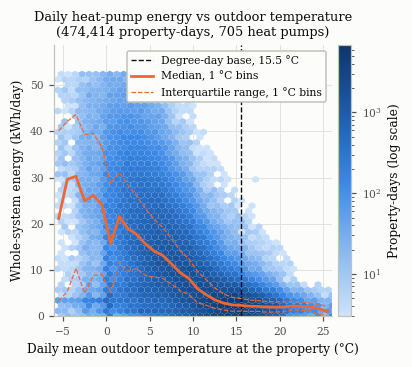

median 25.5 kWh/day below 0 °C vs 2.08 kWh/day above 16 °C (12.3x)


In [9]:
x, y = temp_days.ext_mean.values, temp_days.kwh.values
bins = binned_stats(x, y, np.arange(np.floor(x.min()), np.ceil(x.max()) + 1, 1.0), min_n=200)
XLO, XHI = bins.centre.min() - 0.5, bins.centre.max() + 0.5
YHI = np.percentile(y, 99.5)

with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 3.2))
    hb = ax.hexbin(x, y, gridsize=40, cmap=SEQ_BLUE_CMAP, bins="log", mincnt=3,
                   extent=(XLO, XHI, 0, YHI), linewidths=0)
    ax.axvline(HDD_BASE, color=INK_PRIMARY, linestyle="--", linewidth=0.9,
               label=f"Degree-day base, {HDD_BASE} °C")
    ax.plot(bins.centre, bins["median"], color=CAT["orange"], linewidth=1.8, label="Median, 1 °C bins")
    ax.plot(bins.centre, bins.q25, color=CAT["orange"], linewidth=0.8, linestyle="--",
            label="Interquartile range, 1 °C bins")
    ax.plot(bins.centre, bins.q75, color=CAT["orange"], linewidth=0.8, linestyle="--")
    ax.set_xlim(XLO, XHI)
    ax.set_ylim(0, YHI * 1.12)
    ax.set_xlabel("Daily mean outdoor temperature at the property (°C)")
    ax.set_ylabel("Whole-system energy (kWh/day)")
    # An opaque legend box, so the degree-day line never runs through the legend text.
    ax.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor=BASELINE, framealpha=1)
    cbar = fig.colorbar(hb, ax=ax, fraction=0.05, pad=0.02)
    cbar.set_label("Property-days (log scale)")
    ax.set_title(f"Daily heat-pump energy vs outdoor temperature\n"
                 f"({len(temp_days):,} property-days, {temp_days.property_id.nunique()} heat pumps)")
    savefig(fig, "EoH1_daily_kwh_vs_temperature")
    plt.show()

cold, warm = np.median(y[x < 0]), np.median(y[x > 16])
print(f"median {cold:.1f} kWh/day below 0 °C vs {warm:.2f} kWh/day above 16 °C ({cold / warm:.1f}x)")

### Figure EoH2 - Winter and summer load profiles

Mean kWh per half-hour over the analysis cohort, for meteorological winter (December-February),
summer (June-August) and the shoulder months, across all three trial winters.

saved -> figures/EoH2_winter_vs_summer_profile.png


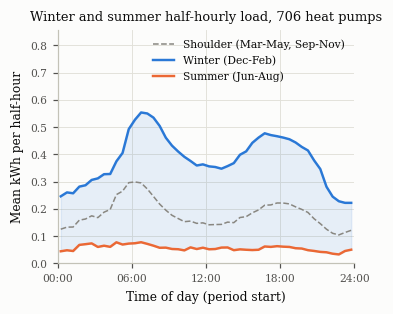

winter uses 6.9x the daily energy of summer (18.3 vs 2.7 kWh/day)


In [10]:
con.register("cohort_ids", pd.DataFrame({"property_id": sorted(COHORT)}))
season_profile = con.execute("""
    SELECT season, slot, avg(kwh) AS mean_kwh
    FROM hh JOIN cohort_ids USING (property_id)
    GROUP BY 1, 2
""").fetchdf()
prof = season_profile.pivot(index="slot", columns="season", values="mean_kwh").sort_index()
winter_daily = analysis[analysis.is_winter].kwh.mean()
summer_daily = analysis[analysis.is_summer].kwh.mean()

with plt.rc_context(COLUMN_RC):
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 2.9))
    xs = prof.index + 0.5
    ax.plot(xs, prof.shoulder, color=INK_MUTED, linewidth=1.0, linestyle="--", label="Shoulder (Mar-May, Sep-Nov)")
    ax.plot(xs, prof.winter, color=WINTER_COLOR, linewidth=1.6, label="Winter (Dec-Feb)")
    ax.plot(xs, prof.summer, color=SUMMER_COLOR, linewidth=1.6, label="Summer (Jun-Aug)")
    ax.fill_between(xs, prof.summer, prof.winter, color=WINTER_COLOR, alpha=0.10)
    hhmm_axis(ax, step_hours=6)
    ax.set_xlim(0, 48)
    # Headroom above the winter peak so the legend never overlaps a curve.
    ax.set_ylim(0, prof.winter.max() * 1.55)
    ax.set_xlabel("Time of day (period start)")
    ax.set_ylabel("Mean kWh per half-hour")
    ax.legend(frameon=False, loc="upper right")
    ax.set_title(f"Winter and summer half-hourly load, {len(COHORT)} heat pumps")
    fig.tight_layout()
    savefig(fig, "EoH2_winter_vs_summer_profile")
    plt.show()

print(f"winter uses {winter_daily / summer_daily:.1f}x the daily energy of summer "
      f"({winter_daily:.1f} vs {summer_daily:.1f} kWh/day)")

### Figure EoH3 - Temperature response of each property

- **`beta_temp`** is the slope of daily kWh on daily mean temperature, fitted on days below 15 °C
  (at least 100 such days). It is the definition used in the feature set.
- **The balance point** is the breakpoint `T_b` of the hinge fit `kWh = a + b·max(0, T_b − T)`,
  chosen on a 0.25 °C grid from 6 to 20 °C to maximise R².

The median balance point sits below the 15.5 °C degree-day base, so the base is slightly inclusive.
Properties at the 20 °C edge of the grid have no interior breakpoint, and that value is a bound.

saved -> figures/EoH3_beta_temp_and_balance_point.png


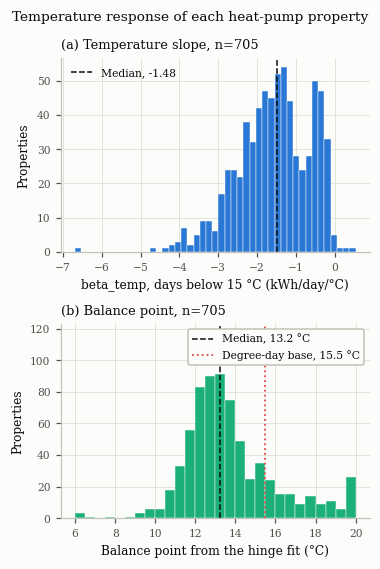

balance point IQR 12.2-14.5 °C; 18 properties at the 20 °C grid edge


In [11]:
bt, bp = temp_response.beta_temp.dropna(), temp_response.balance_point.dropna()

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.2))
    ax = axes[0]
    ax.hist(bt, bins=45, color=CAT["blue"], edgecolor=SURFACE, linewidth=0.3)
    ax.axvline(bt.median(), color=INK_PRIMARY, linestyle="--", linewidth=1.0,
               label=f"Median, {bt.median():.2f}")
    ax.set_xlabel("beta_temp, days below 15 °C (kWh/day/°C)")
    ax.set_ylabel("Properties")
    ax.legend(frameon=False, loc="upper left")
    ax.set_title(f"(a) Temperature slope, n={len(bt)}", loc="left")

    ax = axes[1]
    counts, *_ = ax.hist(bp, bins=np.arange(6, 20.5, 0.5), color=CAT["aqua"], edgecolor=SURFACE, linewidth=0.3)
    ax.set_ylim(0, counts.max() * 1.35)   # headroom so the legend sits above the bars
    ax.axvline(bp.median(), color=INK_PRIMARY, linestyle="--", linewidth=1.0,
               label=f"Median, {bp.median():.1f} °C")
    ax.axvline(HDD_BASE, color=CAT["red"], linestyle=":", linewidth=1.2,
               label=f"Degree-day base, {HDD_BASE} °C")
    ax.set_xlabel("Balance point from the hinge fit (°C)")
    ax.set_ylabel("Properties")
    ax.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor=BASELINE, framealpha=1)
    ax.set_title(f"(b) Balance point, n={len(bp)}", loc="left")

    fig.suptitle("Temperature response of each heat-pump property", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EoH3_beta_temp_and_balance_point")
    plt.show()

print(f"balance point IQR {bp.quantile(.25):.1f}-{bp.quantile(.75):.1f} °C; "
      f"{(bp >= BP_GRID.max()).sum()} properties at the 20 °C grid edge")

### Figure EoH4 - Heat map by month and time of day

Each cell is the mean kWh per half-hour of the standalone heat pump (whole-system electricity,
with no household load added) across the analysis cohort, for that month and time of day. The colour
scale (0 to 1.05 kWh) is shared with the LCL heat map (Figure LCL6) and with Figure HP_J3 of
`04_hp_linkage_lcl_eoh`, the combined household and heat-pump load, so heat-pump load can be read
against gas and electric-only household load, and against the combined load, directly.

saved -> figures/EoH4_month_by_timeofday_heatmap.png


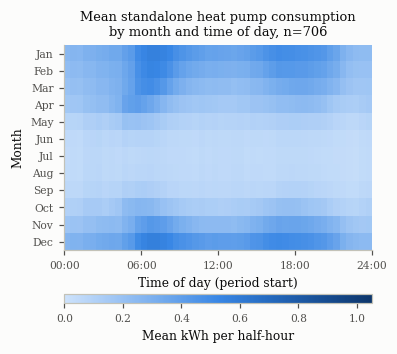

max cell 0.566 kWh (shared scale tops out at 1.05)


In [12]:
month_slot = con.execute("""
    SELECT month, slot, avg(kwh) AS mean_kwh FROM hh JOIN cohort_ids USING (property_id) GROUP BY 1, 2
""").fetchdf()
mat = month_slot.pivot(index="month", columns="slot", values="mean_kwh").reindex(index=range(1, 13), columns=range(48))

with plt.rc_context(COLUMN_RC):
    # Same layout as Figure LCL6 (horizontal colour bar underneath), so the two read side by side.
    fig, ax = plt.subplots(figsize=(COL_WIDTH, 3.1), layout="constrained")
    im = ax.imshow(mat.values, aspect="auto", origin="upper", cmap=SEQ_BLUE_CMAP,
                   vmin=0, vmax=HEATMAP_VMAX, extent=[0, 48, 12, 0])
    hhmm_axis(ax, step_hours=6)
    ax.set_yticks(np.arange(12) + 0.5)
    ax.set_yticklabels(MONTH_LABELS)
    ax.set_xlabel("Time of day (period start)")
    ax.set_ylabel("Month")
    ax.grid(False)
    cbar = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.08, pad=0.02, aspect=35)
    cbar.set_label("Mean kWh per half-hour")
    ax.set_title(f"Mean standalone heat pump consumption\nby month and time of day, n={len(COHORT)}")
    savefig(fig, "EoH4_month_by_timeofday_heatmap")
    plt.show()
print(f"max cell {np.nanmax(mat.values):.3f} kWh (shared scale tops out at {HEATMAP_VMAX})")

### Figure EoH5 - Coverage and enrolment, by delivery contractor

(a) Days with at least one usable reading, per property, as a share of each contractor's
properties so the three share an axis; dashed lines mark each contractor's median. (b) Properties reporting on each day; the shaded bands are
the three winters (December to February). Enrolment was staggered: installation ran through 2020
and 2021 and monitoring equipment was removed from 2022, so the three winters carry different
numbers of properties. This is why per-property statistics are computed first and pooled afterwards.
This figure uses every metered property with usable data, not only the analysis cohort.

saved -> figures/EoH5_coverage.png


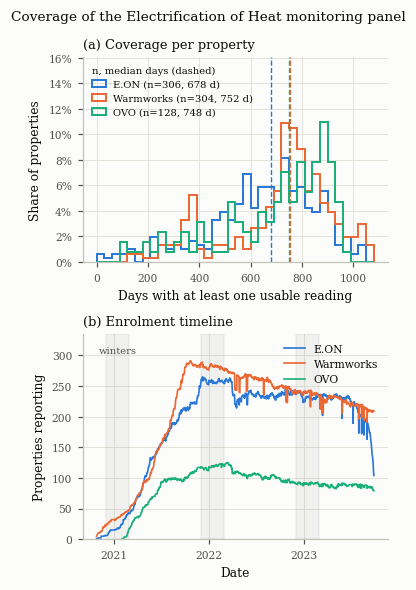

            count   mean    std    min    25%    50%    75%     max
contractor                                                         
E.ON        306.0  651.0  209.0   15.0  544.0  678.0  790.0  1048.0
Warmworks   304.0  711.0  208.0  125.0  631.0  752.0  841.0  1061.0
OVO         128.0  686.0  224.0  105.0  544.0  748.0  859.0   961.0
peak properties reporting: 669 on 2021-12-06


In [13]:
cov = property_day.assign(contractor=property_day.property_id.map(meta_all.contractor))
days_per_prop = cov.groupby(["contractor", "property_id"]).size().rename("n_days").reset_index()
active = cov.groupby(["date", "contractor"]).property_id.nunique().unstack("contractor").reindex(columns=CONTRACTORS)

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.4))

    ax = axes[0]
    bins = np.arange(0, days_per_prop.n_days.max() + 31, 30)
    for c in CONTRACTORS:
        d = days_per_prop.loc[days_per_prop.contractor == c, "n_days"]
        ax.hist(d, bins=bins, weights=np.full(len(d), 1 / len(d)), histtype="step", linewidth=1.3,
                color=CONTRACTOR_COLORS[c], label=f"{c} (n={len(d):,}, {int(d.median())} d)")
        ax.axvline(d.median(), color=CONTRACTOR_COLORS[c], linestyle="--", linewidth=0.9)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.4)
    ax.set_xlabel("Days with at least one usable reading")
    ax.set_ylabel("Share of properties")
    ax.set_title("(a) Coverage per property", loc="left")
    ax.legend(frameon=False, loc="upper left", title="n, median days (dashed)", title_fontsize=6.5,
              fontsize=6.5, handlelength=1.4, alignment="left")

    ax = axes[1]
    for c in CONTRACTORS:
        ax.plot(active.index, active[c], color=CONTRACTOR_COLORS[c], linewidth=1.1, label=c)
    for y0, y1 in [("2020-12-01", "2021-03-01"), ("2021-12-01", "2022-03-01"), ("2022-12-01", "2023-03-01")]:
        ax.axvspan(pd.Timestamp(y0), pd.Timestamp(y1), color=INK_MUTED, alpha=0.10)
    ax.text(pd.Timestamp("2021-01-15"), active.max().max() * 1.03, "winters",
            ha="center", va="bottom", fontsize=6.5, color=INK_SECONDARY)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_ylim(0, active.max().max() * 1.15)
    ax.set_xlabel("Date")
    ax.set_ylabel("Properties reporting")
    ax.set_title("(b) Enrolment timeline", loc="left")
    ax.legend(frameon=False, loc="upper right")

    fig.suptitle("Coverage of the Electrification of Heat monitoring panel", fontsize=9)
    fig.tight_layout()
    savefig(fig, "EoH5_coverage")
    plt.show()

print(days_per_prop.groupby("contractor").n_days.describe().round(0).reindex(CONTRACTORS))
print(f"peak properties reporting: {int(active.sum(axis=1).max())} on {active.sum(axis=1).idxmax():%Y-%m-%d}")

## 5. Notes and limitations

- The energy columns are cumulative meter registers, so they have to be differenced, and the rule
  for outage gaps matters more than any spike filter (section 2).
- Whole-system energy includes immersion and back-up heaters. Where they are metered separately
  they are about 4–5% of annual energy; elsewhere they are unmeasured.
- The cohort is mostly detached and semi-detached houses replacing gas boilers (Table EoH_T2), so
  it isn't representative of GB housing.
- Hybrids give the weakest signal, because their boiler covers the coldest days (Table EoH_T3).
- Enrolment was staggered, so each winter covers a different set of properties. Statistics are
  computed per property before pooling for that reason.
- Temperature comes from a sensor at each property, so a badly placed sensor skews that property's
  temperature response.